<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture provenance](README.md)

# 01 · Reconcile statement entries, not repeated transaction details

A bank-statement entry can carry several transaction-detail records. If the parser repeats the entry amount on each detail row, summing those rows changes the money total. We will identify the correct grain, reconcile opening and closing balances with exact decimal arithmetic, and show why filtering small entries changes the comparison.

**Two synthetic camt.053 statements, no real payment data.** EUR and USD stay separate throughout. The real pinned worker parses local XML; no account access or financial transaction occurs. A matching arithmetic identity does not prove authenticity, completeness outside these files or acceptance by a payment network.

## Choose the local entry filter

`MIN_ENTRY_AMOUNT` is a decimal string in each statement's own currency, with at most two fractional digits and range **0.00–1000.00**. An entry is selected when its nonnegative amount is **at least** this threshold. Default **"0.00"** retains every eligible booked entry; the experiment uses **"100.00"**. Applying the same numeric threshold to EUR and USD does not make their purchasing power equivalent.

The files state a period of **2026-01-02 00:00:00 through 23:59:59 UTC**, inclusive. Booking/value fields are dates, with no inferred time of day. Restart Kernel → Run All after editing.

In [1]:
MIN_ENTRY_AMOUNT = "0.00"  # Decimal currency units, inclusive; experiment: "100.00"

In [2]:
import hashlib
import json
import re
from decimal import Decimal
from pathlib import Path
from xml.etree import ElementTree

import haybarn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(MIN_ENTRY_AMOUNT, str) and re.fullmatch(r"[0-9]{1,4}(?:[.][0-9]{1,2})?", MIN_ENTRY_AMOUNT)
assert Decimal("0") <= Decimal(MIN_ENTRY_AMOUNT) <= Decimal("1000")
manifest = json.loads(Path("fixtures/manifest.json").read_text())
for name, digest in manifest["files"].items():
    payload = Path("fixtures", name).read_bytes()
    assert hashlib.sha256(payload).hexdigest() == digest
    root = ElementTree.fromstring(payload)
    assert sum(el.tag.rsplit("}", 1)[-1] == "Stmt" for el in root.iter()) == 1
fingerprint = hashlib.sha256(json.dumps(manifest["files"], sort_keys=True).encode()).hexdigest()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Source: synthetic camt.053 fixtures · statement date 2026-01-02 · v0.4.0 worker · currencies never aggregated",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.95))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-iso20022/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-iso20022/notebooks/pyproject.toml.

## Parse headers and preserve the input relation when exploding details

`github-auto` downloads the platform release, verifies its SHA-256 and caches it. No local worker build is required. The pinned release predates a multi-statement raw-document fix, so these inputs deliberately contain exactly **one statement per file**, verified before parsing.

The exploder takes a relation. Pass statement identity and `raw`; the worker repeats those input columns on every output row. Its `amount` is **Ntry/Amt**, not an independently reported TxDtls amount. `entry_idx` identifies the Ntry within its statement; `tx_idx` identifies the flattened detail. A bare entry without TxDtls still emits one row.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'iso20022' (
 TYPE vgi,
 LOCATION 'github-auto://Query-farm/vgi-iso20022@v0.4.0'
);
CREATE TABLE statements AS SELECT * FROM iso20022.main.camt053_read('fixtures/*.xml');
CREATE TABLE details AS
SELECT * FROM iso20022.main.camt053_entries(
 (SELECT stmt_id,raw FROM statements)
);

,Count


In [4]:
%%sql diagnostics <<
SELECT s.stmt_id,s.account_ccy,s.entry_count AS header_entries,
 count(d.entry_idx) AS exploded_rows,count(DISTINCT d.entry_idx) AS distinct_entries,
 count(*) FILTER (WHERE d.status='PDNG') AS pending_detail_rows
FROM statements s LEFT JOIN details d USING(stmt_id)
GROUP BY s.stmt_id,s.account_ccy,s.entry_count ORDER BY s.stmt_id;

In [5]:
display(diagnostics)
assert con.execute("SELECT count(*)=count(DISTINCT stmt_id) FROM statements").fetchone()[0]
assert (diagnostics.header_entries == diagnostics.distinct_entries).all()
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT stmt_id,entry_idx,tx_idx FROM details GROUP BY ALL HAVING count(*)<>1)"
    ).fetchone()[0]
    == 0
)
# Every repeated entry-level field must be complete and identical before MIN can safely recover it.
assert (
    con.execute("""SELECT count(*) FROM (SELECT stmt_id,entry_idx FROM details GROUP BY ALL
 HAVING count(amount)<>count(*) OR count(DISTINCT amount)<>1
 OR count(ccy)<>count(*) OR count(DISTINCT ccy)<>1
 OR count(credit_debit)<>count(*) OR count(DISTINCT credit_debit)<>1
 OR count(status)<>count(*) OR count(DISTINCT status)<>1)""").fetchone()[0]
    == 0
)
prose(
    f"The headers describe **{int(diagnostics.header_entries.sum())} entries**, while the exploder returns **{int(diagnostics.exploded_rows.sum())} rows**. The difference is detail expansion, not additional account movements. Fixture fingerprint: `{fingerprint}`. Identity and repeated-field checks pass before aggregation."
)

,stmt_id,account_ccy,header_entries,exploded_rows,distinct_entries,pending_detail_rows
0,STMT-EUR,EUR,6,9,6,1
1,STMT-USD,USD,2,3,2,0


The headers describe **8 entries**, while the exploder returns **12 rows**. The difference is detail expansion, not additional account movements. Fixture fingerprint: `33870c6bcf8eb198d33575dd0dc36de36874cb3fc31fdbfcfd6e6643e3f0a194`. Identity and repeated-field checks pass before aggregation.

## Recover one amount per entry, then apply sign and eligibility

Group by `(stmt_id, entry_idx)`, using the already-checked repeated fields. Do not deduplicate by amount: two different entries can legitimately have equal values. Do not divide an entry amount by the number of details and call the result a transaction amount; no allocation rule is supplied.

For this fixture, booked `CRDT` entries contribute positively and booked `DBIT` entries negatively. `reversal` remains descriptive: the sign is already expressed by `CdtDbtInd`, so it is not flipped a second time. Pending entries are shown but excluded from the booked-balance identity. An unknown amount, sign, status or mismatched currency would make this reconciliation inapplicable; the checks stop rather than substitute zero.

In [6]:
%%sql
CREATE TABLE entries AS
SELECT stmt_id,entry_idx,min(amount) AS amount,min(ccy) AS ccy,
 min(credit_debit) AS credit_debit,min(status) AS status,
 bool_or(reversal) AS reversal,count(*) AS detail_rows
FROM details GROUP BY stmt_id,entry_idx;
CREATE TABLE booked AS
SELECT e.*,CASE credit_debit WHEN 'CRDT' THEN amount WHEN 'DBIT' THEN -amount END AS signed_amount
FROM entries e WHERE status='BOOK';
CREATE TABLE selected AS
SELECT * FROM booked WHERE amount>=CAST('{{MIN_ENTRY_AMOUNT}}' AS DECIMAL(38,9));

,Count


In [7]:
%%sql movements <<
SELECT stmt_id,entry_idx,CAST(amount AS VARCHAR) AS amount,ccy,credit_debit,status,
 reversal,detail_rows FROM entries ORDER BY stmt_id,entry_idx;

In [8]:
display(movements)
assert (
    con.execute(
        "SELECT count(*) FROM entries WHERE amount<0 OR credit_debit NOT IN ('CRDT','DBIT') OR status NOT IN ('BOOK','PDNG')"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM entries e JOIN statements s USING(stmt_id) WHERE e.ccy IS DISTINCT FROM s.account_ccy OR e.ccy IS DISTINCT FROM s.ccy"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM statements WHERE opening_balance IS NULL OR closing_balance IS NULL"
    ).fetchone()[0]
    == 0
)
assert con.execute("SELECT count(*) FROM booked WHERE signed_amount IS NULL").fetchone()[0] == 0
assert con.execute("SELECT typeof(amount) FROM booked LIMIT 1").fetchone()[0] == "DECIMAL(38,9)"
prose(
    f"**{con.execute('SELECT count(*) FROM booked').fetchone()[0]} booked entries** enter the full reconciliation. **{con.execute("SELECT count(*) FROM entries WHERE status='PDNG'").fetchone()[0]} pending entry** stays outside it. Monetary calculations remain `DECIMAL(38,9)` in SQL; displayed amount strings preserve those exact values. Floating point is used only to draw charts."
)

,stmt_id,entry_idx,amount,ccy,credit_debit,status,reversal,detail_rows
0,STMT-EUR,0,600.100000000,EUR,CRDT,BOOK,False,2
1,STMT-EUR,1,0.200000000,EUR,CRDT,BOOK,False,1
2,STMT-EUR,2,250.250000000,EUR,DBIT,BOOK,False,3
3,STMT-EUR,3,1.400000000,EUR,DBIT,BOOK,False,1
4,STMT-EUR,4,10.000000000,EUR,DBIT,BOOK,True,1
5,STMT-EUR,5,1000.000000000,EUR,CRDT,PDNG,False,1
6,STMT-USD,0,200.000000000,USD,CRDT,BOOK,False,2
7,STMT-USD,1,50.000000000,USD,DBIT,BOOK,False,1


**7 booked entries** enter the full reconciliation. **1 pending entry** stays outside it. Monetary calculations remain `DECIMAL(38,9)` in SQL; displayed amount strings preserve those exact values. Floating point is used only to draw charts.

## Quantify the repeated-amount trap without mixing currencies

Compare signed net movement at the correct entry grain with an intentionally naive sum of booked detail rows. The latter repeats Ntry/Amt whenever there is more than one detail. Credits and debits can partly offset the error, so a small discrepancy would not make the method valid.

In [9]:
%%sql
CREATE TABLE grain_comparison AS
SELECT b.stmt_id,b.ccy,sum(b.signed_amount) AS entry_net,
 sum(b.signed_amount*b.detail_rows) AS naive_detail_net
FROM booked b GROUP BY b.stmt_id,b.ccy;

,Count


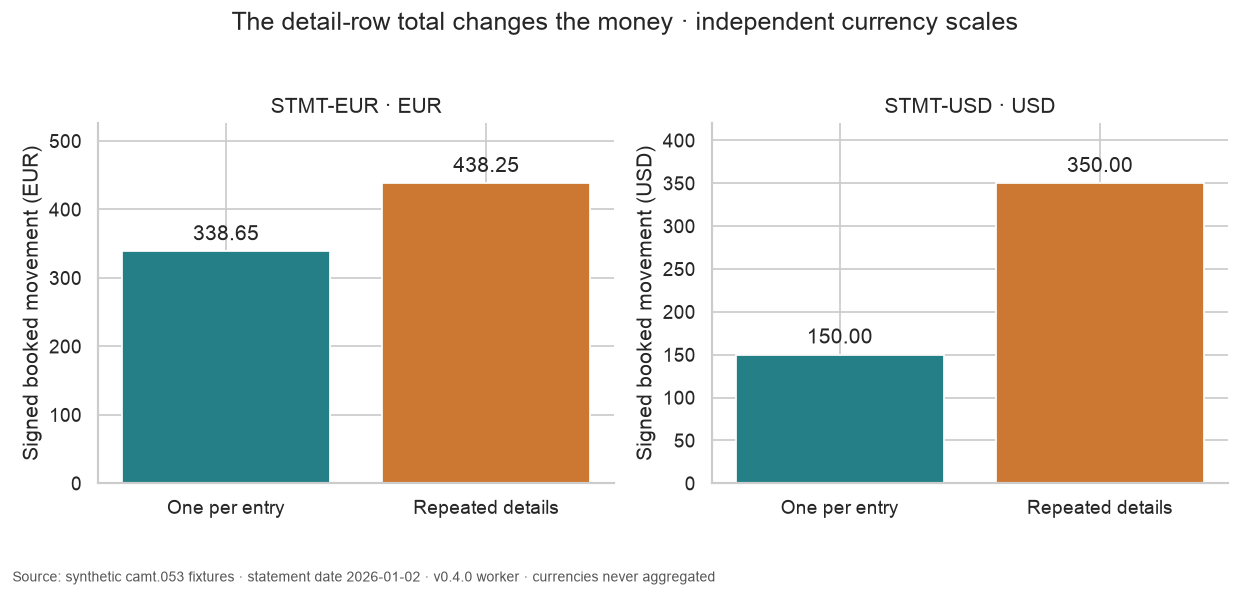

**STMT-EUR:** correct net movement **338.65 EUR**, naive detail sum **438.25 EUR**, difference **+99.60 EUR**. The difference is a row-grain error, not an exchange-rate effect.

**STMT-USD:** correct net movement **150.00 USD**, naive detail sum **350.00 USD**, difference **+200.00 USD**. The difference is a row-grain error, not an exchange-rate effect.

In [10]:
grain = con.execute("SELECT * FROM grain_comparison ORDER BY ccy").df()
fig, axes = plt.subplots(1, len(grain), figsize=(10, 4.7), squeeze=False)
for ax, r in zip(axes.flat, grain.itertuples(), strict=True):
    bars = ax.bar(
        ["One per entry", "Repeated details"],
        [float(r.entry_net), float(r.naive_detail_net)],
        color=["#247f86", "#cc7832"],
    )
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.axhline(0, color="#555555", linewidth=0.8)
    ax.set(title=f"{r.stmt_id} · {r.ccy}", ylabel=f"Signed booked movement ({r.ccy})")
    ax.margins(y=0.2)
fig.suptitle("The detail-row total changes the money · independent currency scales")
finish(fig)
for stmt, ccy, correct, naive in con.execute("SELECT * FROM grain_comparison ORDER BY ccy").fetchall():
    prose(
        f"**{stmt}:** correct net movement **{correct:.2f} {ccy}**, naive detail sum **{naive:.2f} {ccy}**, difference **{naive - correct:+.2f} {ccy}**. The difference is a row-grain error, not an exchange-rate effect."
    )

## Reconcile the full statement and expose the filtered comparison

For each statement, expected closing balance is `opening + sum(signed booked entries)`. The residual is `reported closing − expected closing`; exact zero is the fixture's reconciliation criterion, without a floating-point tolerance.

The filtered view intentionally keeps the original opening/closing balances. Its residual equals the signed movement of omitted entries, so it describes a population mismatch. It is not evidence of a bank error. An empty selected subset contributes an exact zero because it contains no movements; unavailable amounts are never converted to zero.

In [11]:
%%sql
CREATE TABLE reconciliation_results AS
SELECT s.stmt_id,s.account_ccy AS ccy,s.opening_balance,s.closing_balance,
 g.entry_net AS full_net,
 coalesce(f.selected_net,CAST(0 AS DECIMAL(38,9))) AS selected_net,
 s.opening_balance+g.entry_net AS full_implied_close,
 s.opening_balance+coalesce(f.selected_net,CAST(0 AS DECIMAL(38,9))) AS selected_implied_close,
 s.closing_balance-(s.opening_balance+g.entry_net) AS full_residual,
 s.closing_balance-(s.opening_balance+coalesce(f.selected_net,CAST(0 AS DECIMAL(38,9)))) AS selected_residual,
 coalesce(f.selected_entries,0) AS selected_entries
FROM statements s JOIN grain_comparison g USING(stmt_id)
LEFT JOIN (SELECT stmt_id,sum(signed_amount) AS selected_net,count(*) AS selected_entries
 FROM selected GROUP BY stmt_id) f USING(stmt_id);

,Count


In [12]:
%%sql reconciliation <<
SELECT stmt_id,ccy,selected_entries,
 CAST(opening_balance AS VARCHAR) AS opening_balance,
 CAST(closing_balance AS VARCHAR) AS reported_close,
 CAST(full_net AS VARCHAR) AS full_net,
 CAST(selected_net AS VARCHAR) AS selected_net,
 CAST(full_residual AS VARCHAR) AS full_residual,
 CAST(selected_residual AS VARCHAR) AS selected_residual
FROM reconciliation_results ORDER BY ccy;

,stmt_id,ccy,selected_entries,opening_balance,reported_close,full_net,selected_net,full_residual,selected_residual
0,STMT-EUR,EUR,5,1000.000000000,1338.650000000,338.650000000,338.650000000,0.000000000,0.000000000
1,STMT-USD,USD,2,-50.000000000,100.000000000,150.000000000,150.000000000,0.000000000,0.000000000


**STMT-EUR:** at an inclusive minimum of **0.00 EUR**, the selected entry count is **5**. Full residual **0.00 EUR**; filtered residual **+0.00 EUR**. The omitted net movement accounts for the filtered residual exactly.

**STMT-USD:** at an inclusive minimum of **0.00 USD**, the selected entry count is **2**. Full residual **0.00 USD**; filtered residual **+0.00 USD**. The omitted net movement accounts for the filtered residual exactly.

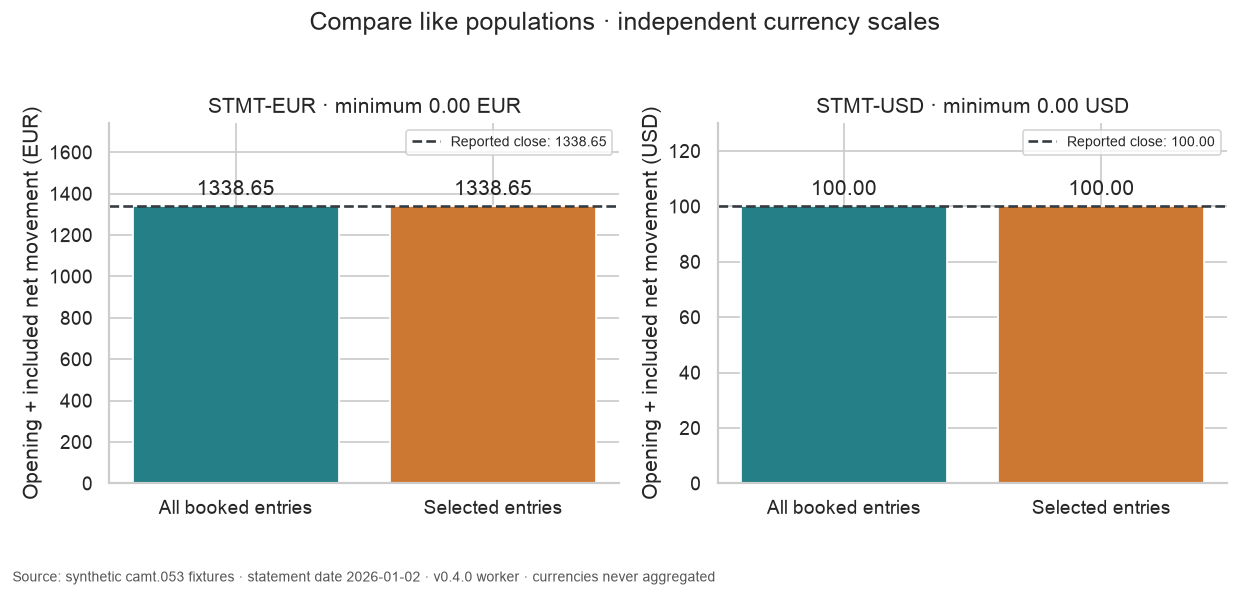

In [13]:
display(reconciliation)
assert con.execute("SELECT bool_and(full_residual=0) FROM reconciliation_results").fetchone()[0]
assert con.execute(
    "SELECT bool_and(selected_residual=full_net-selected_net) FROM reconciliation_results"
).fetchone()[0]
assert (
    con.execute("SELECT count(*) FROM selected").fetchone()[0]
    <= con.execute("SELECT count(*) FROM booked").fetchone()[0]
)
for r in reconciliation.itertuples():
    prose(
        f"**{r.stmt_id}:** at an inclusive minimum of **{Decimal(MIN_ENTRY_AMOUNT):.2f} {r.ccy}**, the selected entry count is **{r.selected_entries}**. Full residual **{Decimal(r.full_residual):.2f} {r.ccy}**; filtered residual **{Decimal(r.selected_residual):+.2f} {r.ccy}**. The omitted net movement accounts for the filtered residual exactly."
    )
result = con.execute("SELECT * FROM reconciliation_results ORDER BY ccy").df()
fig, axes = plt.subplots(1, len(result), figsize=(10, 4.7), squeeze=False)
for ax, r in zip(axes.flat, result.itertuples(), strict=True):
    bars = ax.bar(
        ["All booked entries", "Selected entries"],
        [float(r.full_implied_close), float(r.selected_implied_close)],
        color=["#247f86", "#cc7832"],
    )
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.axhline(
        float(r.closing_balance),
        color="#343a40",
        linestyle="--",
        label=f"Reported close: {r.closing_balance:.2f}",
    )
    ax.set(
        title=f"{r.stmt_id} · minimum {Decimal(MIN_ENTRY_AMOUNT):.2f} {r.ccy}",
        ylabel=f"Opening + included net movement ({r.ccy})",
    )
    ax.margins(y=0.3)
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Compare like populations · independent currency scales")
finish(fig)

## Experiment: omit small entries while keeping the statement fixed

Change only `MIN_ENTRY_AMOUNT` from **"0.00" to "100.00"** in a separate run. Predict fewer selected entries, but do not assume the residual's sign: excluding debits and excluding credits move the comparison in opposite directions. Compare the selected count, filtered residual and implied closing balance for each currency.

The file fingerprint, full booked reconciliation and repeated-detail comparison must remain unchanged. Restore **"0.00"** afterwards. The experiment demonstrates how a filter changes a reconciliation population; it does not determine materiality or recommend a real accounting policy.

In [14]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)